# EDA изображений

Посмотрим фотографии и разметку Helmet, No-Helmet и Person. После очистки соберём рабочую выборку.

In [1]:
from pathlib import Path
import hashlib
import json

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
import numpy as np
import pandas as pd
from PIL import Image
import seaborn as sns
from sklearn.model_selection import train_test_split
import yaml

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'config.yaml').is_file()
)
config = yaml.safe_load((ROOT / 'config.yaml').read_text(encoding='utf-8'))
settings = config['datasets']['safety']

SEED = config['seed']
RAW_DIR = ROOT / settings['raw_dir']
TARGET_SIZE = settings['target_size']
PREVIEW_SIZE = settings['preview_per_class']
SPLIT_PARTS = pd.Series(settings['split_parts'], dtype=int)
SPLITS = list(SPLIT_PARTS.index)
MAX_CLIP = settings['max_bbox_clip_px']
BOX_COLS = ['x', 'y', 'w', 'h']

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({
    'figure.dpi': 105, 'figure.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
})

In [2]:
image_parts, box_parts = [], []
for split in SPLITS:
    path = RAW_DIR / split / '_annotations.coco.json'
    data = json.loads(path.read_text(encoding='utf-8'))
    categories = {row['id']: row['name'] for row in data['categories']}

    photos = pd.DataFrame(data['images']).rename(columns={'id': 'image_id'})
    boxes = pd.DataFrame(data['annotations']).rename(columns={'id': 'annotation_id'})
    photos = photos[['image_id', 'file_name', 'width', 'height']].copy()
    boxes = boxes[['annotation_id', 'image_id', 'category_id', 'bbox']].copy()

    video_tags = []
    for image in data['images']:
        tags = image.get('extra', {}).get('user_tags', [])
        youtube = [tag for tag in tags if tag.startswith('youtube:')]
        video_tags.append(youtube[0] if youtube else None)
    photos['video_tag'] = video_tags

    for frame in (photos, boxes):
        frame['source_split'] = split
        frame['image_key'] = split + '/' + frame['image_id'].astype(str)
    image_parts.append(photos)
    box_parts.append(boxes)

images = pd.concat(image_parts, ignore_index=True)
annotations = pd.concat(box_parts, ignore_index=True)
images['source_name'] = images['file_name'].str.split('.rf.', n=1, regex=False).str[0]

video_names = images['source_name'].str.extract(
    r'(?i)^(.+?mp4|video\d+)[_-](?:frame[-_])?\d+(?:_|$)', expand=False,
).str.lower()
video_tags = images.groupby('source_name')['video_tag'].transform('first')
images['series'] = video_tags.fillna('video:' + video_names)
images['split_group'] = images['series'].fillna('name:' + images['source_name'])

CLASS_NAMES = [
    name for category_id, name in categories.items()
    if category_id in annotations['category_id'].unique()
]
CLASS_COLORS = dict(zip(CLASS_NAMES, sns.color_palette('colorblind', len(CLASS_NAMES))))

In [3]:
pixel_hashes = []
for photo in images.itertuples(index=False):
    with Image.open(RAW_DIR / photo.source_split / photo.file_name) as image:
        rgb = image.convert('RGB')
        digest = hashlib.sha256(f'{rgb.width}x{rgb.height}:RGB:'.encode())
        digest.update(rgb.tobytes())
        pixel_hashes.append(digest.hexdigest())

images['pixel_hash'] = pixel_hashes

In [4]:
def box_excess(boxes):
    edges = pd.DataFrame({
        'left': -boxes['x'],
        'top': -boxes['y'],
        'right': boxes['x'] + boxes['w'] - boxes['width'],
        'bottom': boxes['y'] + boxes['h'] - boxes['height'],
    })
    return edges.max(axis=1).clip(lower=0)


coordinates = pd.DataFrame(annotations['bbox'].tolist(), columns=BOX_COLS).astype(float)
objects = annotations.drop(columns='bbox').join(coordinates).merge(
    images[['image_key', 'width', 'height']], on='image_key', validate='many_to_one',
)
objects['class_name'] = objects['category_id'].map(categories)
objects['excess_px'] = box_excess(objects)
objects['area_pct'] = 100 * objects['w'] * objects['h'] / (objects['width'] * objects['height'])

BOX_KEY = ['image_key', 'category_id', *BOX_COLS]
valid_size = np.isfinite(objects[BOX_COLS]).all(axis=1) & objects[['w', 'h']].gt(0).all(axis=1)
object_sizes = objects.loc[valid_size]

## Смотрим данные

Возьмём по несколько случайных фото с каждым классом. Разметка здесь исходная, для своих фотографий правила зададим отдельно.

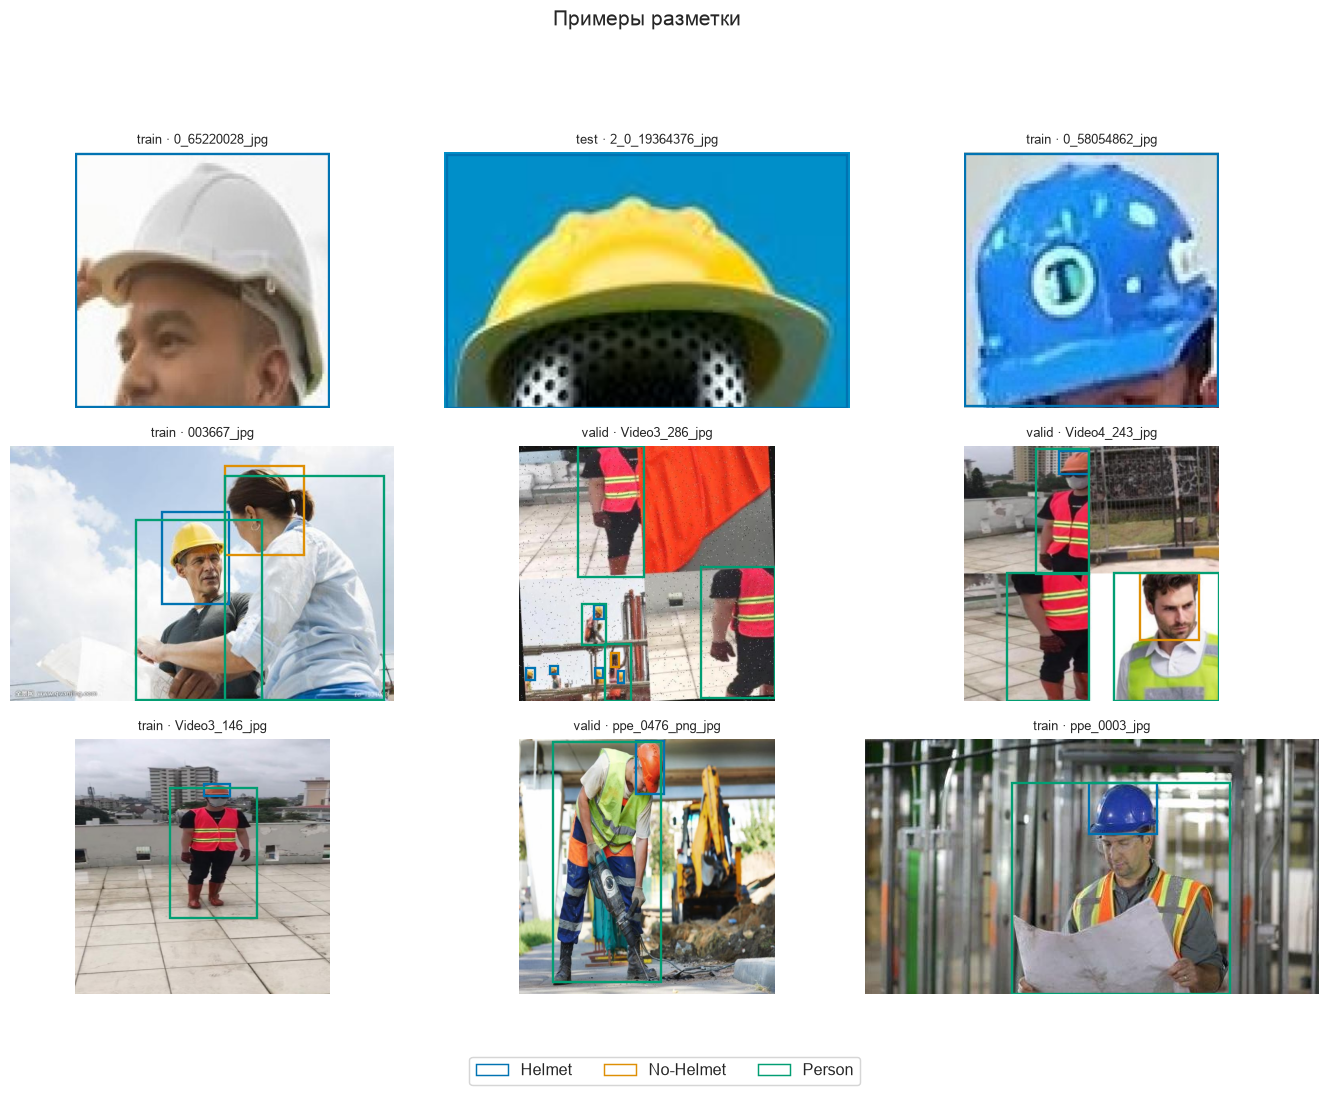

In [5]:
def show_gallery(keys, photos, boxes, title, focus=None):
    keys = list(dict.fromkeys(keys))
    if not keys:
        return

    photo_index = photos.set_index('image_key')
    columns = min(3, len(keys))
    rows = (len(keys) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(4.4 * columns, 3.5 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')

    for ax, key in zip(axes.flat, keys):
        row = photo_index.loc[key]
        split = row.get('split', row['source_split'])
        caption = f'{split} · {row["source_name"][:32]}'
        left, top, right, bottom = 0, 0, int(row['width']), int(row['height'])
        if focus is not None:
            x, y, w, h = focus[key]
            caption += f'\n{w:g} × {h:g} px'
            padding = max(w, h)
            left = max(0, int(np.floor(x - padding)))
            top = max(0, int(np.floor(y - padding)))
            right = min(right, int(np.ceil(x + w + padding)))
            bottom = min(bottom, int(np.ceil(y + h + padding)))

        with Image.open(RAW_DIR / row['source_split'] / row['file_name']) as image:
            view = image.crop((left, top, right, bottom)).convert('RGB')
        view.thumbnail((900, 900))
        ax.imshow(view, extent=(left, right, bottom, top))
        image_boxes = boxes.loc[boxes['image_key'].eq(key)]
        for box in image_boxes.itertuples(index=False):
            ax.add_patch(Rectangle(
                (box.x, box.y), box.w, box.h, fill=False,
                edgecolor=CLASS_COLORS[box.class_name], linewidth=1.6,
            ))
        ax.set_xlim(left, right)
        ax.set_ylim(bottom, top)
        ax.set_title(caption, fontsize=9)

    fig.suptitle(title)
    fig.legend(handles=[
        Patch(facecolor='none', edgecolor=color, label=name)
        for name, color in CLASS_COLORS.items()
    ], loc='lower center', ncols=len(CLASS_NAMES))
    fig.tight_layout(rect=(0, 0.07, 1, 0.92))
    plt.show()


rng = np.random.default_rng(SEED)
example_keys = []
for name in CLASS_NAMES:
    class_keys = object_sizes.loc[object_sizes['class_name'].eq(name), 'image_key']
    pool = images.loc[images['image_key'].isin(class_keys)].sort_values('image_key')
    sample = pool.sample(n=min(PREVIEW_SIZE, len(pool)), random_state=rng)
    example_keys.extend(sample['image_key'])

show_gallery(example_keys, images, object_sizes, 'Примеры разметки')

,Фото,Рамки
Класс,,
Helmet,17929,27817
No-Helmet,2936,4668
Person,10469,25891


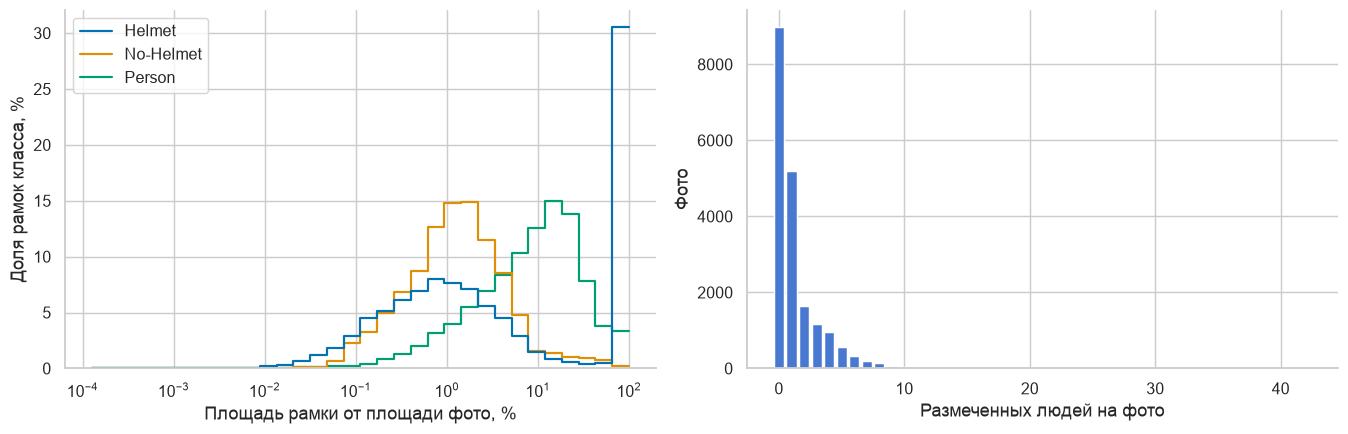

In [6]:
def class_counts(boxes):
    counts = boxes.groupby('class_name')['image_key'].agg(['nunique', 'size'])
    return (
        counts.reindex(CLASS_NAMES, fill_value=0)
        .rename(columns={'nunique': 'Фото', 'size': 'Рамки'})
        .rename_axis('Класс')
    )


def count_people(photos, boxes):
    counts = boxes.loc[boxes['class_name'].eq('Person')].groupby('image_key').size()
    return photos['image_key'].map(counts).fillna(0).astype(int)


display(class_counts(objects))

people = count_people(images, object_sizes)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
sns.histplot(
    data=object_sizes, x='area_pct', hue='class_name', hue_order=CLASS_NAMES,
    palette=CLASS_COLORS, log_scale=True, bins=32, element='step', fill=False,
    stat='percent', common_norm=False, ax=axes[0],
)
axes[0].set(xlabel='Площадь рамки от площади фото, %', ylabel='Доля рамок класса, %')
axes[0].get_legend().set_title(None)
people_distribution = people.value_counts().sort_index()
axes[1].bar(people_distribution.index, people_distribution)
axes[1].set(xlabel='Размеченных людей на фото', ylabel='Фото')
fig.tight_layout()
plt.show()

No-Helmet встречается заметно реже Helmet. На одном фото может быть несколько объектов, поэтому фото и рамки считаем отдельно. У Helmet есть пик около 100% площади: в наборе много крупных фрагментов с касками.

Теперь посмотрим крайние случаи: много размеченных людей и самые мелкие каски или головы. Маленькие рамки покажем крупнее.

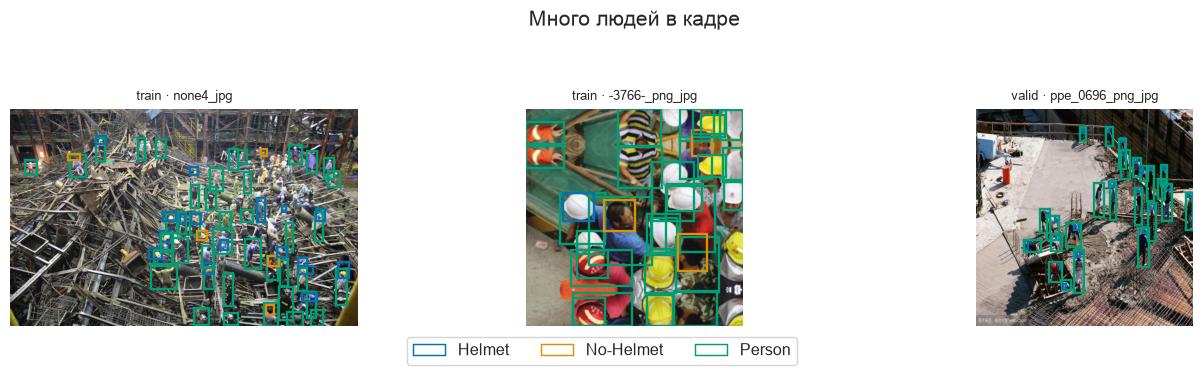

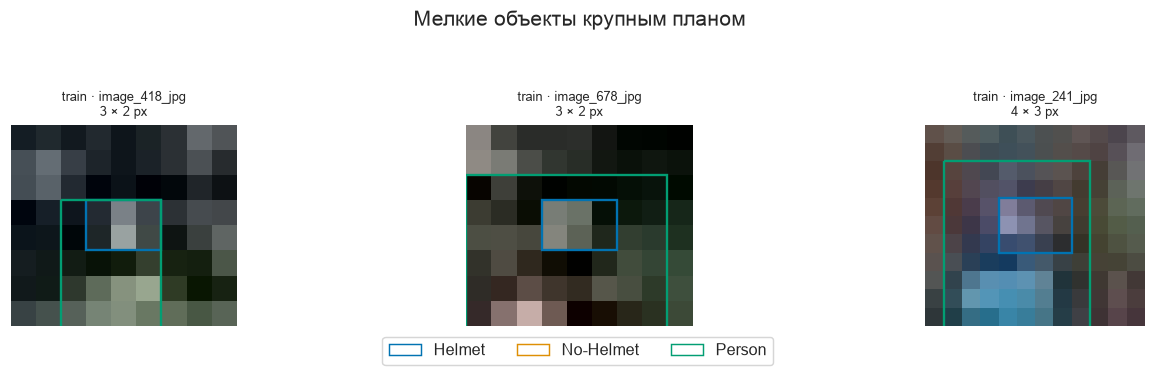

In [7]:
crowded = people.nlargest(PREVIEW_SIZE).index
show_gallery(
    images.loc[crowded, 'image_key'], images, object_sizes, 'Много людей в кадре',
)

small_boxes = object_sizes.loc[object_sizes['class_name'].ne('Person')].sort_values(
    ['area_pct', 'image_key', 'annotation_id'],
).drop_duplicates('image_key').head(PREVIEW_SIZE)
show_gallery(
    small_boxes['image_key'], images, object_sizes, 'Мелкие объекты крупным планом',
    focus={row.image_key: (row.x, row.y, row.w, row.h) for row in small_boxes.itertuples()},
)

Есть рамки всего в несколько пикселей. Эти фотографии тоже оставляем в наборе.

## Чистим данные

Убираем точные дубли. Если у одинаковых фото разная разметка, исключаем всю группу. Небольшой выход рамки за край исправляем, а фото с остальными ошибочными рамками убираем.

In [8]:
signature_rows = objects[BOX_KEY].drop_duplicates().sort_values(BOX_KEY)
signature_rows['box_tuple'] = list(
    signature_rows[['category_id', *BOX_COLS]].itertuples(index=False, name=None)
)
signatures = signature_rows.groupby('image_key', sort=False)['box_tuple'].agg(tuple)
images['annotation_signature'] = images['image_key'].map(signatures).fillna('')
versions = images.groupby('pixel_hash')['annotation_signature'].nunique()
conflict_hashes = versions.index[versions.gt(1)]

corrected = objects.copy()
clippable = valid_size & objects['excess_px'].gt(0) & objects['excess_px'].le(MAX_CLIP)
for start, length, limit in [('x', 'w', 'width'), ('y', 'h', 'height')]:
    end = objects[start] + objects[length]
    needs_clip = clippable & (objects[start].lt(0) | end.gt(objects[limit]))
    boundary = objects.loc[needs_clip, limit]
    left = objects.loc[needs_clip, start].clip(lower=0, upper=boundary)
    right = end.loc[needs_clip].clip(lower=0, upper=boundary)
    corrected.loc[needs_clip, start] = left
    corrected.loc[needs_clip, length] = right - left

bad_boxes = (
    ~valid_size
    | ~corrected[['w', 'h']].gt(0).all(axis=1)
    | (box_excess(corrected) > 0)
)
reject_reason = pd.Series('', index=images.index, dtype='string')
rules = {
    'Некорректные рамки': images['image_key'].isin(corrected.loc[bad_boxes, 'image_key']),
    'Дубли с разной разметкой': images['pixel_hash'].isin(conflict_hashes),
}
for reason, mask in rules.items():
    reject_reason.loc[reject_reason.eq('') & mask] = reason

eligible = images.loc[reject_reason.eq('')].sort_values('image_key')
duplicate_reason = 'Дубли с одинаковой разметкой'
reject_reason.loc[eligible.index[eligible['pixel_hash'].duplicated()]] = duplicate_reason
clean_images = images.loc[reject_reason.eq('')].copy()
kept_boxes = corrected.loc[corrected['image_key'].isin(clean_images['image_key'])]
clean_boxes = kept_boxes.drop_duplicates(BOX_KEY).copy()
clean_boxes['area_pct'] = (
    100 * clean_boxes['w'] * clean_boxes['h'] / (clean_boxes['width'] * clean_boxes['height'])
)

reasons_by_image = pd.Series(reject_reason.to_numpy(), index=images['image_key'])
cleaning = pd.DataFrame({
    'Убрано фото': reject_reason.value_counts(),
    'Убрано рамок': objects['image_key'].map(reasons_by_image).value_counts(),
}).reindex([*rules, duplicate_reason]).fillna(0).astype(int)
cleaning.loc['Повторные рамки'] = [0, len(kept_boxes) - len(clean_boxes)]
display(cleaning.loc[cleaning.gt(0).any(axis=1)])

clipped_count = int(clippable.loc[clean_boxes.index].sum())
print(f'Поправили рамки у края: {clipped_count}')

,Убрано фото,Убрано рамок
Некорректные рамки,1,2
Дубли с разной разметкой,334,836
Дубли с одинаковой разметкой,121,145


Поправили рамки у края: 487


## Собираем выборку

В исходном test почти нет No-Helmet, поэтому делим данные заново.

Сначала оставим один файл на исходное имя, потом один случайный кадр на видео. Серии вроде worker_5_mp4 определяем по именам файлов, остальные известные видео по YouTube-тегам.

При отборе и разбиении сохраним примерно ту долю редкого класса, которая осталась после удаления повторов.

In [9]:
def sample_one(photos, group, rng):
    return (
        photos.sort_values('image_key')
        .sample(frac=1, random_state=rng)
        .drop_duplicates(group)
        .sort_values('image_key')
        .reset_index(drop=True)
    )


rng = np.random.default_rng(SEED)
unique_images = sample_one(clean_images, 'source_name', rng)
candidates = sample_one(unique_images, 'split_group', rng)

unique_boxes = clean_boxes.loc[clean_boxes['image_key'].isin(unique_images['image_key'])]
candidate_boxes = clean_boxes.loc[clean_boxes['image_key'].isin(candidates['image_key'])]
rare_class = candidate_boxes.groupby('class_name')['image_key'].nunique().idxmin()
rare_keys = candidate_boxes.loc[candidate_boxes['class_name'].eq(rare_class), 'image_key']
candidates['has_rare_class'] = candidates['image_key'].isin(rare_keys)

In [10]:
selected, _ = train_test_split(
    candidates, train_size=TARGET_SIZE,
    stratify=candidates['has_rare_class'], random_state=SEED,
)
split_sizes = (TARGET_SIZE * SPLIT_PARTS / SPLIT_PARTS.sum()).round().astype(int)

train, holdout = train_test_split(
    selected, train_size=int(split_sizes['train']),
    stratify=selected['has_rare_class'], random_state=SEED,
)
valid, test = train_test_split(
    holdout, train_size=int(split_sizes['valid']),
    stratify=holdout['has_rare_class'], random_state=SEED,
)

working_images = pd.concat([
    train.assign(split='train'),
    valid.assign(split='valid'),
    test.assign(split='test'),
], ignore_index=True)
working_boxes = clean_boxes.merge(
    working_images[['image_key', 'split']], on='image_key', how='inner', validate='many_to_one',
)

## Что осталось после отбора

Проверим размер набора и долю No-Helmet на каждом шаге. В таблице считаем фотографии с этим классом, а не отдельные рамки.

In [11]:
stages = {
    'Исходный': (images, objects),
    'После очистки': (clean_images, clean_boxes),
    'Без повторов имён': (unique_images, unique_boxes),
    'По кадру на видео': (candidates, candidate_boxes),
    'Рабочий': (working_images, working_boxes),
}
summary_rows = []
for name, (photos, boxes) in stages.items():
    rare_photos = boxes.loc[boxes['class_name'].eq(rare_class), 'image_key'].nunique()
    summary_rows.append({
        'Набор': name,
        'Фото': len(photos),
        'Рамки': len(boxes),
        f'Фото с {rare_class}': rare_photos,
        f'{rare_class}, %': round(100 * rare_photos / len(photos), 1),
    })
display(pd.DataFrame(summary_rows).set_index('Набор'))

,Фото,Рамки,Фото с No-Helmet,"No-Helmet, %"
Набор,,,,
Исходный,19456,58376,2936,15.1
После очистки,19000,57393,2875,15.1
Без повторов имён,12137,32681,1036,8.5
По кадру на видео,11353,29691,946,8.3
Рабочий,4000,10631,333,8.3


Больше всего доля No-Helmet меняется, когда оставляем один файл на исходное имя. При случайном отборе и разбиении она почти не меняется.

Посмотрим итоговые классы и разбиения. В конце выведем случайные фото из каждой части.

In [12]:
final_photo_counts = (
    working_boxes.drop_duplicates(['image_key', 'category_id'])
    .groupby(['split', 'class_name']).size().unstack(fill_value=0)
    .reindex(index=SPLITS, columns=CLASS_NAMES, fill_value=0)
)

manifest = working_images[['split', 'source_split', 'image_id', 'file_name']].sort_values(
    ['split', 'source_split', 'image_id'],
).reset_index(drop=True)

display(class_counts(working_boxes))
split_summary = pd.DataFrame({
    'Фото': working_images['split'].value_counts().reindex(SPLITS),
    'Рамки': working_boxes['split'].value_counts().reindex(SPLITS),
})
split_summary = split_summary.join(final_photo_counts.add_prefix('Фото с '))
split_summary[f'{rare_class}, %'] = (
    100 * final_photo_counts[rare_class] / split_summary['Фото']
).round(1)
display(split_summary.rename_axis('Выборка'))

,Фото,Рамки
Класс,,
Helmet,3607,5717
No-Helmet,333,558
Person,1772,4356


,Фото,Рамки,Фото с Helmet,Фото с No-Helmet,Фото с Person,"No-Helmet, %"
Выборка,,,,,,
train,3200,8542,2877,266,1434,8.3
valid,400,1069,362,34,174,8.5
test,400,1020,368,33,164,8.2


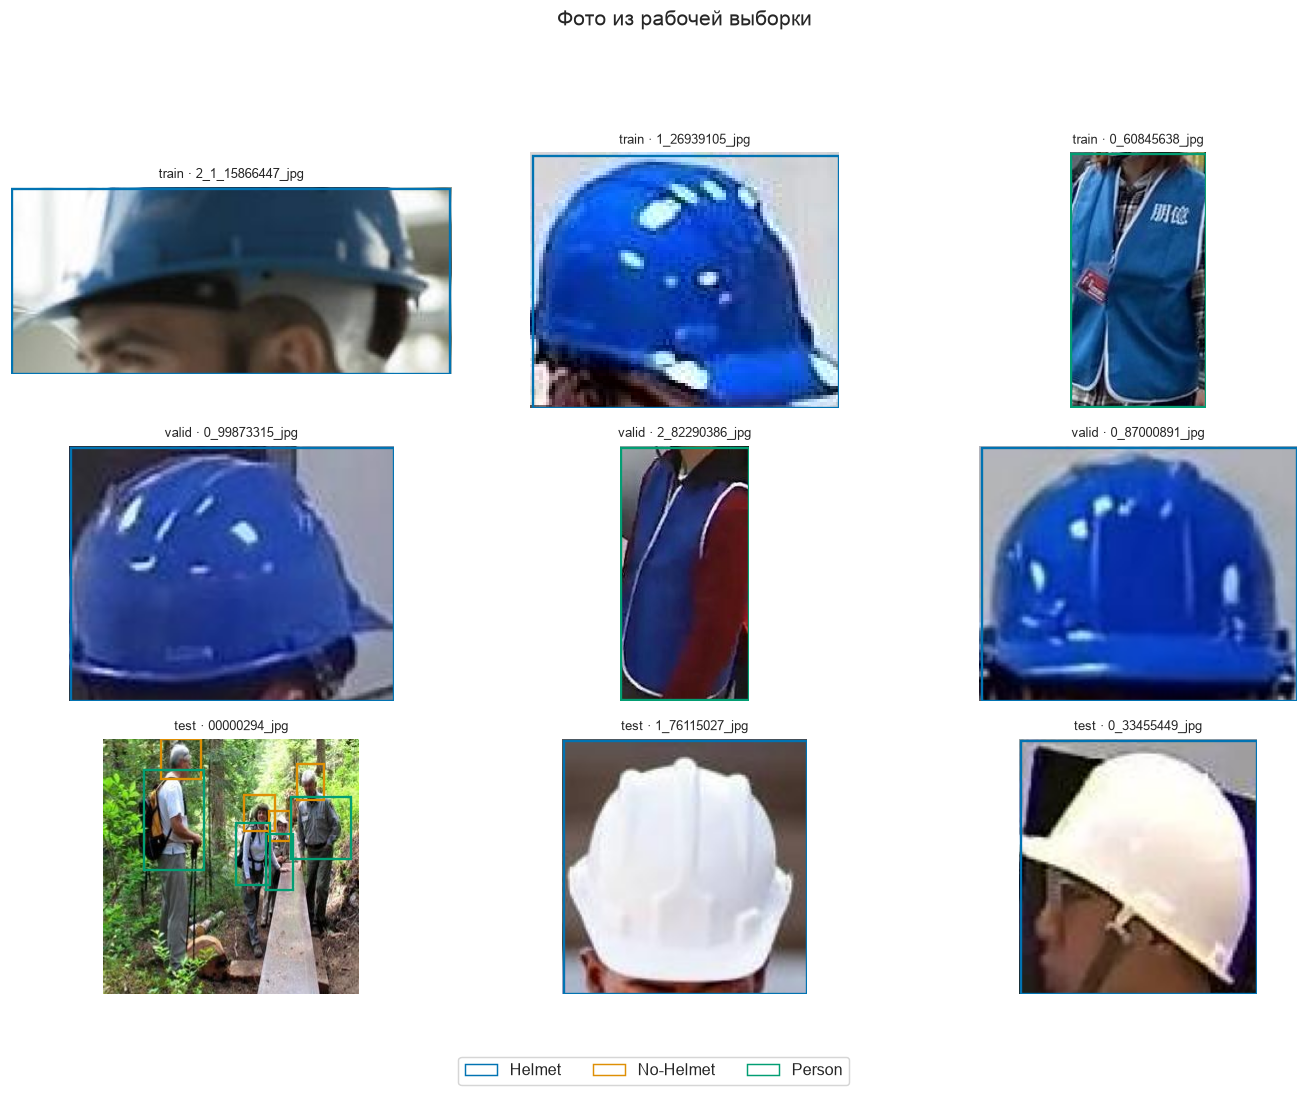

In [13]:
preview_size = min(PREVIEW_SIZE, int(working_images['split'].value_counts().min()))
final_examples = working_images.groupby('split', sort=False).sample(
    n=preview_size, random_state=SEED,
)
show_gallery(
    final_examples['image_key'], working_images, working_boxes, 'Фото из рабочей выборки',
)

Рабочая выборка собрана. Файлы перечислены в manifest, рамки находятся в working_boxes.

Из каждого распознанного видео оставили один кадр. Если связь между фотографиями не видна по именам или тегам, похожие кадры ещё могут остаться.